# Dataset overview

Summary of the refined tick data written by `utils/select_columns.py`: how many events and IDs
there are, when trading is active on each day, how events are spread over the IDs, and
how activity looks over time at five resolutions.

An *event* is one row of the refined file: an update for one ID that carries a `Last` price.

In [1]:
from datetime import datetime, timedelta
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import StrMethodFormatter

# Output of utils/select_columns.py
DATA = Path("../refined/small.csv")

# Number of days the dataset covers, counted from the first day in the file
DAYS = 7

# Each ID has one row per day with Last 0 at 00:00:00.000. These are not trades,
# so they are counted in the first table and left out of everything after it.
EXCLUDE_PLACEHOLDERS = True

In [2]:
# Chart styling
SURFACE, INK, INK_SECONDARY, MUTED = "#fcfcfb", "#0b0b0b", "#52514e", "#898781"
GRID, AXIS = "#e1e0d9", "#c3c2b7"
BLUE = "#2a78d6"
BLUES = LinearSegmentedColormap.from_list("blues", ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
WIDTH = 18  # figure width in inches

plt.rcParams.update({
    "figure.dpi": 120,
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "font.family": "sans-serif",
    "font.sans-serif": ["Helvetica Neue", "Arial", "DejaVu Sans"],
    "text.color": INK,
    "axes.titlelocation": "left",
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.labelcolor": INK_SECONDARY,
    "axes.edgecolor": AXIS,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.spines.left": False,
    "axes.grid": True,
    "axes.grid.axis": "y",
    "axes.axisbelow": True,
    "grid.color": GRID,
    "grid.linewidth": 0.8,
    "xtick.color": AXIS,
    "ytick.color": AXIS,
    "xtick.labelcolor": MUTED,
    "ytick.labelcolor": MUTED,
    "ytick.left": False,
})
THOUSANDS = StrMethodFormatter("{x:,.0f}")

pl.Config.set_thousands_separator(",")
pl.Config.set_tbl_rows(20)
pl.Config.set_tbl_hide_column_data_types(True)
pl.Config.set_tbl_hide_dataframe_shape(True);

## Load

The file is read once. `Trading date` and `Trading time` are combined into one timestamp.

In [3]:
if not DATA.is_file():
    raise SystemExit(f"{DATA} not found: run utils/select_columns.py first")

time = (pl.col("Trading date") + " " + pl.col("Trading time")).str.to_datetime("%d-%m-%Y %H:%M:%S%.3f")
rows = (
    pl.scan_csv(DATA, schema_overrides={"Last": pl.Float64})
    .select(
        pl.col("ID").cast(pl.Categorical),
        pl.col("SecType").cast(pl.Categorical),
        time.alias("time"),
        ((pl.col("Trading time") == "00:00:00.000") & (pl.col("Last") == 0)).alias("placeholder"),
    )
    .collect()
)

events = rows.lazy()
if EXCLUDE_PLACEHOLDERS:
    events = events.filter(~pl.col("placeholder"))

# The period covered: DAYS whole days from midnight of the first day in the file
first_day = rows["time"].min().date()
START = datetime.combine(first_day, datetime.min.time())
days = pl.date_range(first_day, first_day + timedelta(days=DAYS - 1), eager=True).alias("Day")
day_labels = days.dt.strftime("%a %d %b").to_list()

## Events and IDs

In [4]:
def count(label, frame):
    return frame.select(pl.lit(label).alias(""), pl.len().alias("Events"), pl.col("ID").n_unique().alias("IDs"))


pl.concat([
    count("All rows in the file", rows.lazy()),
    count("Placeholder rows", rows.lazy().filter("placeholder")),
    count("Events", events),
    count("  equities (SecType E)", events.filter(pl.col("SecType") == "E")),
    count("  indices (SecType I)", events.filter(pl.col("SecType") == "I")),
]).collect()

,Events,IDs
"""All rows in the file""","59,708,052","5,182"
"""Placeholder rows""","31,242","5,182"
"""Events""","59,676,810","5,016"
""" equities (SecType E)""","10,593,848","2,534"
""" indices (SecType I)""","49,082,962","2,482"


## Active trading hours per day

The table gives the first and last event of each day and the number of clock hours that
contain at least one event. The chart shows how many events fall in each hour.

In [5]:
# Events in every second of the period; the hourly and binned charts are sums of this
per_second = np.zeros(DAYS * 86_400, dtype=np.int64)
seconds = events.group_by((pl.col("time") - START).dt.total_seconds().alias("second")).len().collect()
per_second[seconds["second"]] = seconds["len"]

per_day = events.group_by(pl.col("time").dt.date().alias("Day")).agg(
    pl.col("time").min().dt.time().alias("First event"),
    pl.col("time").max().dt.time().alias("Last event"),
    pl.col("time").dt.hour().n_unique().alias("Active hours"),
    pl.len().alias("Events"),
    pl.col("ID").n_unique().alias("IDs"),
).collect()

(
    days.to_frame()
    .join(per_day, on="Day", how="left")
    .with_columns(pl.col("Day").dt.strftime("%a %d %b %Y"), pl.col("Active hours", "Events", "IDs").fill_null(0))
)

Day,First event,Last event,Active hours,Events,IDs
"""Mon 08 Nov 2021""",07:00:00.021,22:35:05.013,16,"11,851,525","4,929"
"""Tue 09 Nov 2021""",07:00:00.530,22:35:05.015,16,"11,957,149","4,932"
"""Wed 10 Nov 2021""",01:00:00,22:35:05.014,17,"12,125,302","4,923"
"""Thu 11 Nov 2021""",07:00:01.013,22:35:03.009,16,"11,892,437","4,908"
"""Fri 12 Nov 2021""",07:00:00.474,22:35:05.010,16,"11,850,397","4,919"
"""Sat 13 Nov 2021""",null,null,0,0,0
"""Sun 14 Nov 2021""",null,null,0,0,0


## Events per ID

IDs ordered from most to fewest events. The same data is drawn twice: on a linear scale,
where the busiest IDs dominate, and on a log scale, where the quiet tail is visible.

In [7]:
per_id = (
    events.group_by(pl.col("ID").cast(pl.String)).agg(pl.len().alias("Events"))
    .sort("Events", "ID", descending=[True, False])
    .with_row_index("Rank", offset=1)
    .collect()
)
per_id

Rank,ID,Events
1,"""A169S8.ETR""","162,379"
2,"""A0X7J3.ETR""","161,830"
3,"""A2FG24.ETR""","160,505"
4,"""A2FG2Q.ETR""","160,504"
5,"""A2FG2R.ETR""","160,504"
6,"""A2FG2S.ETR""","160,504"
7,"""A0Z3NF.ETR""","160,401"
8,"""720327.ETR""","160,400"
9,"""720328.ETR""","160,400"
10,"""846741.ETR""","160,384"


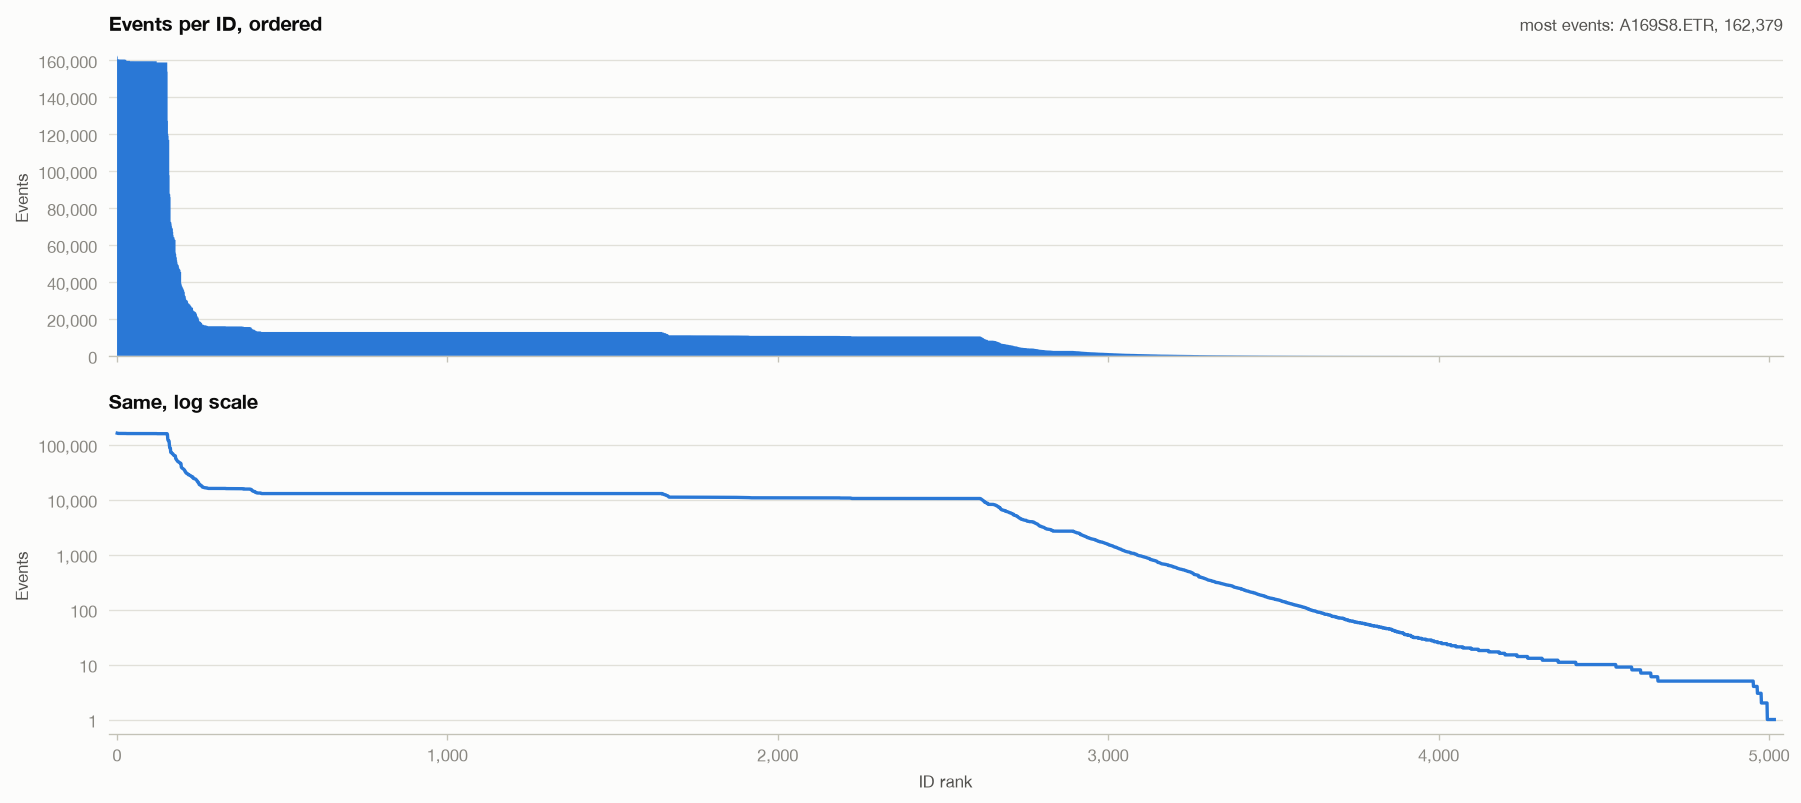

In [8]:
counts = per_id["Events"].to_numpy()
rank = per_id["Rank"].to_numpy()

fig, (linear, log) = plt.subplots(2, 1, figsize=(WIDTH, 7.5), sharex=True)
linear.stairs(counts, np.arange(counts.size + 1) + 0.5, fill=True, color=BLUE)
linear.set_title("Events per ID, ordered")
linear.set_title(f"most events: {per_id['ID'][0]}, {counts[0]:,}",
                 loc="right", color=INK_SECONDARY, fontsize=10, fontweight="normal")
log.plot(rank, counts, color=BLUE, linewidth=2)
log.set_yscale("log")
log.set_title("Same, log scale")
log.set_xlabel("ID rank")
for ax in (linear, log):
    ax.yaxis.set_major_formatter(THOUSANDS)
    ax.xaxis.set_major_formatter(THOUSANDS)
    ax.set_ylabel("Events")
    ax.margins(x=0.005)
plt.show()

## Activity over time

Events per period over the whole dataset, at five bin sizes. Bars touch, with no gaps.

At this width one pixel column covers about 5 minutes, so the charts finer than that have
more bars than pixels (604,800 one-second bars). Their bars are grouped into 5-minute
columns and each column is drawn twice: the tallest bar in it (light) and the average bar
(solid). The tallest bar keeps short bursts visible; the average shows the typical level.

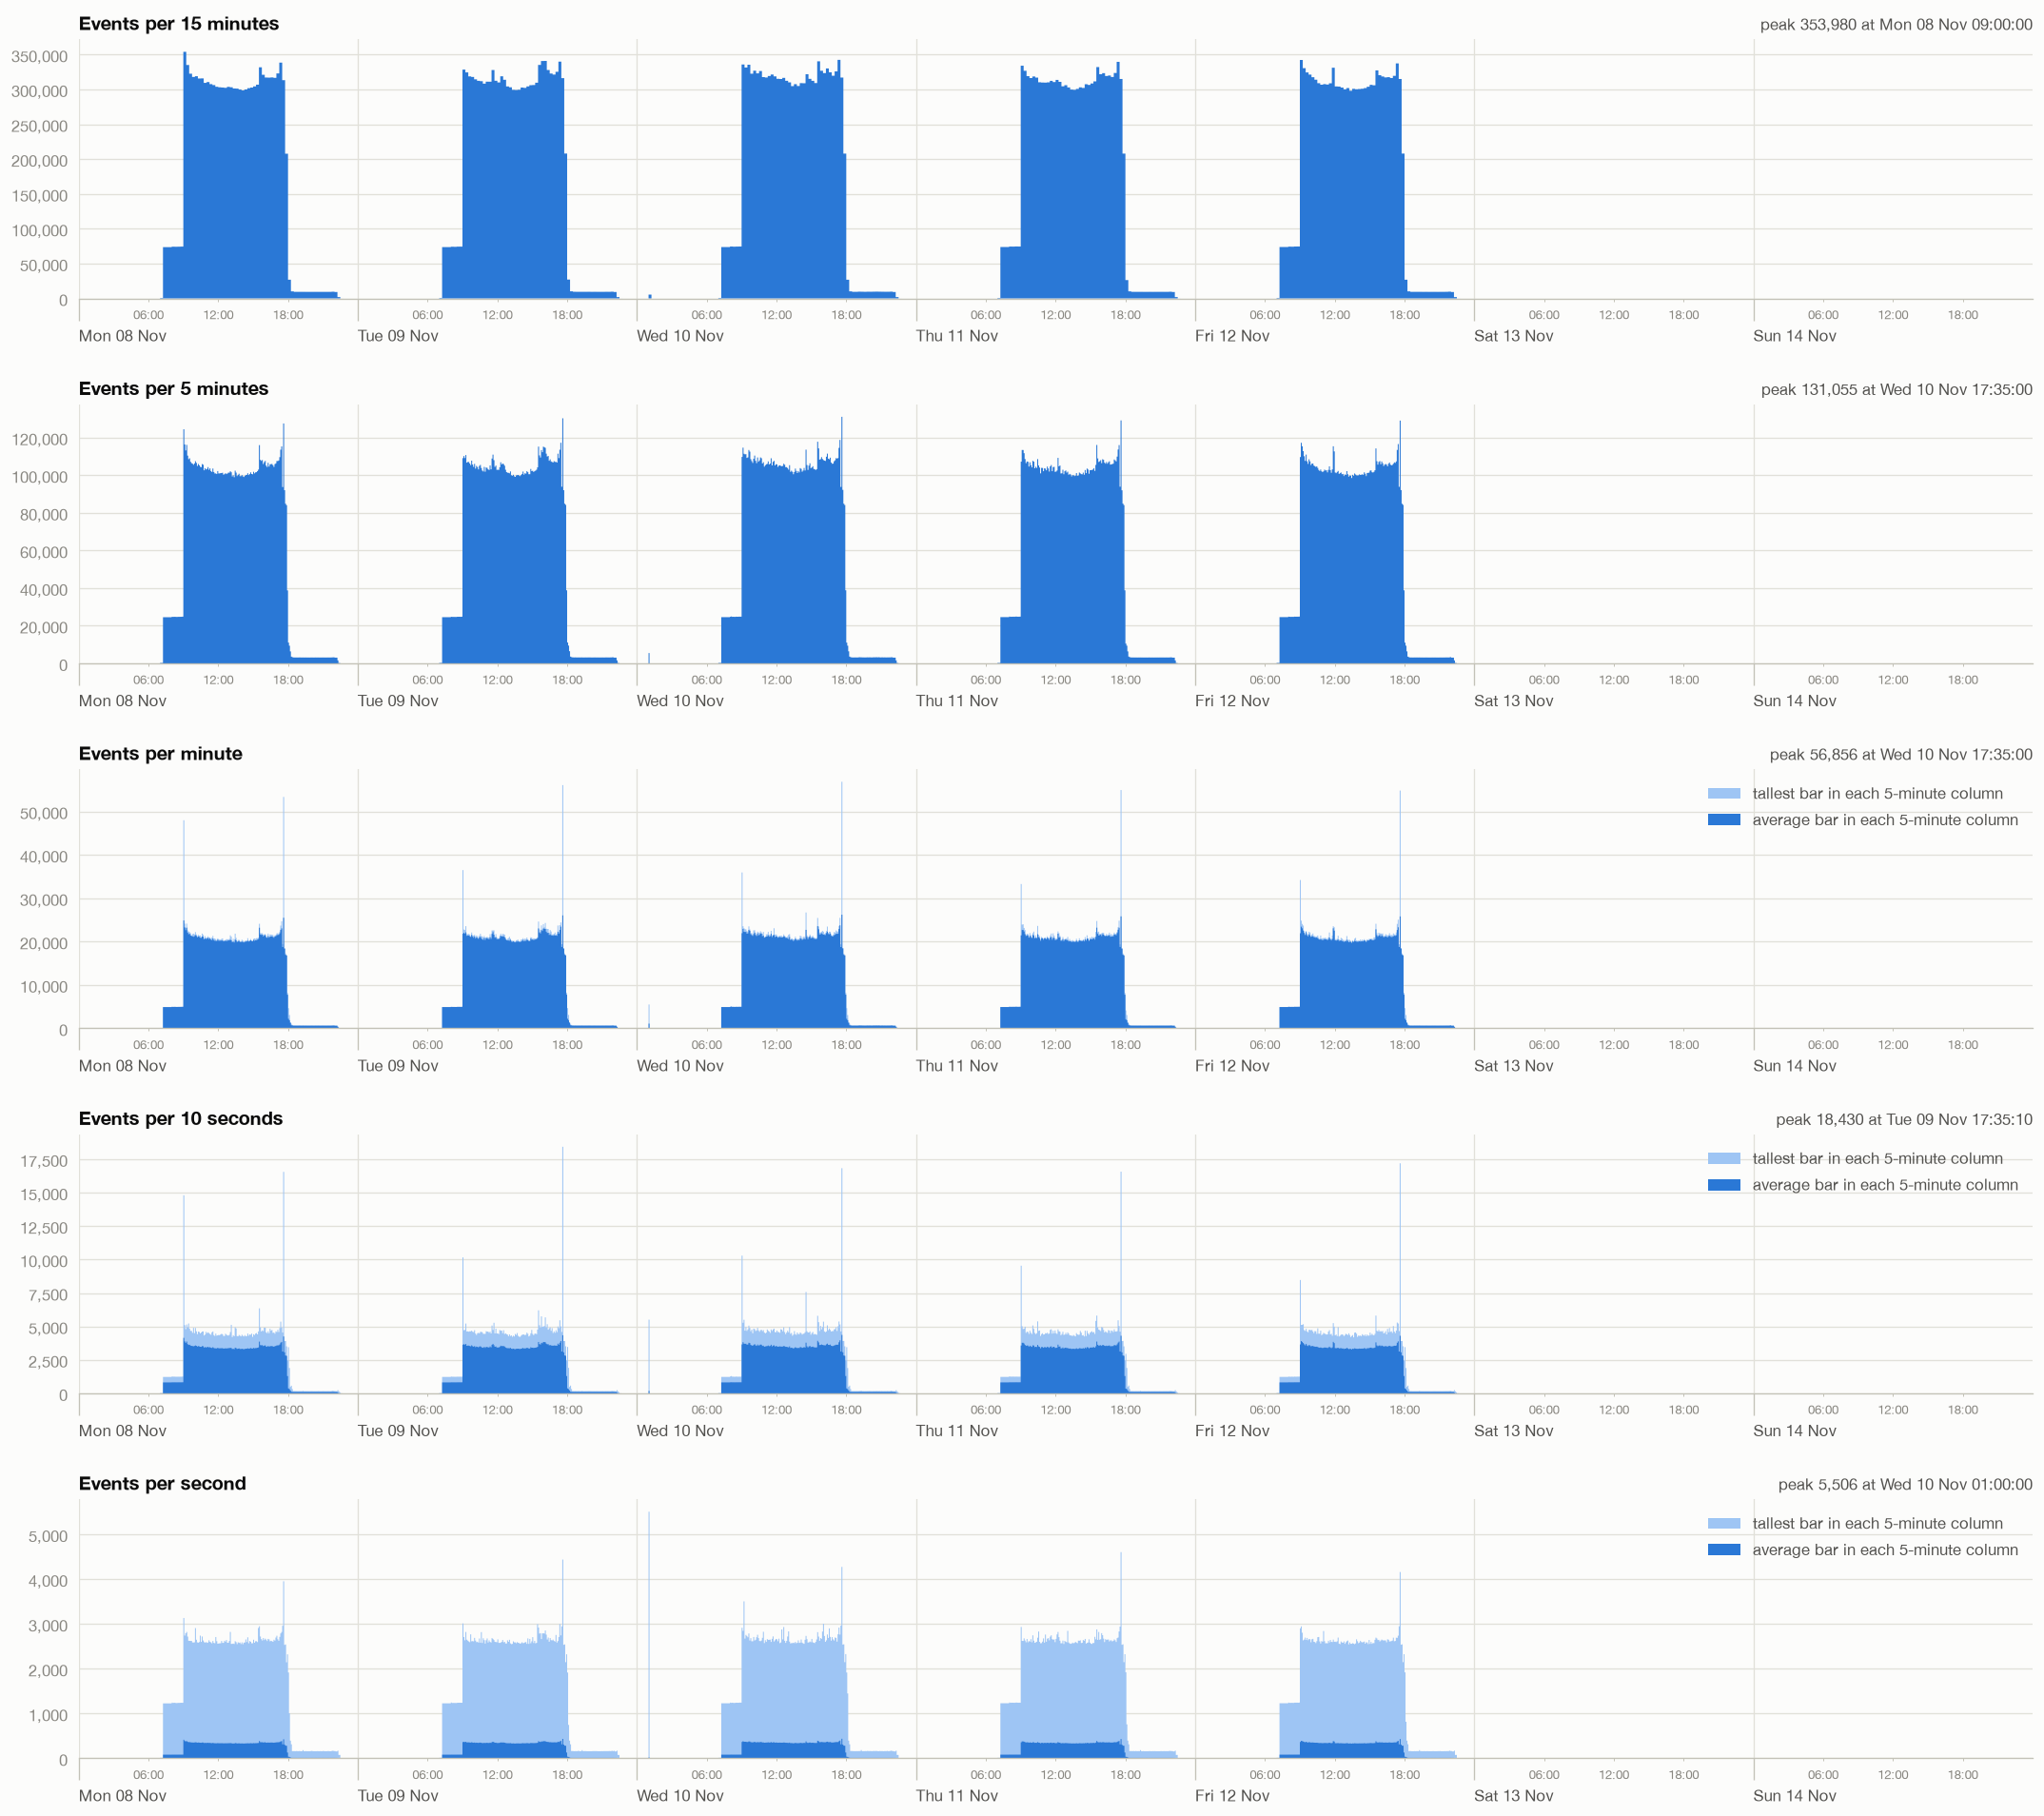

In [9]:
BINS = {"15 minutes": 900, "5 minutes": 300, "minute": 60, "10 seconds": 10, "second": 1}
COLUMN = 300  # seconds of data per pixel column
LIGHT_BLUE = "#9ec5f4"

origin = np.datetime64(START, "s")
day_starts = origin + np.arange(DAYS) * np.timedelta64(1, "D")

fig, axes = plt.subplots(len(BINS), 1, figsize=(WIDTH, 3.2 * len(BINS)), sharex=True)
for ax, (label, width) in zip(axes, BINS.items()):
    counts = per_second.reshape(-1, width).sum(axis=1)
    if width < COLUMN:
        columns = counts.reshape(-1, COLUMN // width)
        edges = origin + np.arange(len(columns) + 1) * np.timedelta64(COLUMN, "s")
        ax.stairs(columns.max(axis=1), edges, fill=True, color=LIGHT_BLUE, label="tallest bar in each 5-minute column")
        ax.stairs(columns.mean(axis=1), edges, fill=True, color=BLUE, label="average bar in each 5-minute column")
        ax.legend(loc="upper right", frameon=False, labelcolor=INK_SECONDARY)
    else:
        edges = origin + np.arange(counts.size + 1) * np.timedelta64(width, "s")
        ax.stairs(counts, edges, fill=True, color=BLUE)
    peak = origin + counts.argmax() * np.timedelta64(width, "s")
    ax.set_title(f"Events per {label}")
    ax.set_title(f"peak {counts.max():,} at {peak.astype(datetime):%a %d %b %H:%M:%S}",
                 loc="right", color=INK_SECONDARY, fontsize=10, fontweight="normal")
    ax.yaxis.set_major_formatter(THOUSANDS)
    ax.set_xticks(day_starts, day_labels, ha="left")
    ax.xaxis.set_minor_locator(mdates.HourLocator(byhour=[6, 12, 18]))
    ax.xaxis.set_minor_formatter(mdates.DateFormatter("%H:%M"))
    ax.tick_params(axis="x", which="both", labelbottom=True)
    ax.tick_params(axis="x", which="major", length=14, labelcolor=INK_SECONDARY)
    ax.tick_params(axis="x", which="minor", labelsize=8)
    ax.grid(True, axis="x", which="major")
    ax.set_xlim(origin, origin + np.timedelta64(DAYS, "D"))
fig.tight_layout(h_pad=2)
plt.show()